## Identify Expression Prediction problems

After trying the revised pipeline on lab data, the results only showed apprxoimately a 20% improvement in MSE. In this notebook we seek to understand noise (biological, measurement, and model-wise) to determine how good of a prediction we can possibly get as well as the variation of gene expression.

### 1. Measurement and raw counts

In [1]:
from pathlib import Path
import gzip
import json
import urllib.request
import urllib.error

import anndata as ad
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.io import mmread

ROOT = Path.home() / "scgpt-cna"

SAMPLE_ID = "C3N-00148-01"
SAMPLE_DIR = Path(
    "/home/akash1/projects/rrg-tperkins/dgladish/Projects/MSc/"
    "benchmarking_spatial_scale/GDC-data/C3N-00148/C3N-00148-01"
)

RNA_DIR = (
    SAMPLE_DIR
    / "single_cell"
    / "dbe28c52-cdbf-477e-a728-9a61fd4a8139"
)
MATRIX_DIR = RNA_DIR / "qc_filtered_bc_feature_matrix"

OUT = ROOT / "measurement_analysis" / SAMPLE_ID
OUT.mkdir(parents=True, exist_ok=True)

assert MATRIX_DIR.is_dir(), MATRIX_DIR
print("Matrix directory:", MATRIX_DIR)

Matrix directory: /home/akash1/projects/rrg-tperkins/dgladish/Projects/MSc/benchmarking_spatial_scale/GDC-data/C3N-00148/C3N-00148-01/single_cell/dbe28c52-cdbf-477e-a728-9a61fd4a8139/qc_filtered_bc_feature_matrix


In [2]:
candidate_file_id = RNA_DIR.name

url = (
    f"https://api.gdc.cancer.gov/files/{candidate_file_id}"
    "?expand=analysis,cases.project,cases.samples"
)

try:
    with urllib.request.urlopen(url, timeout=30) as response:
        gdc_response = json.load(response)

except (urllib.error.URLError, TimeoutError) as exc:
    print("Could not retrieve GDC metadata:", exc)
    print("Continue with the matrix audit below.")

else:
    metadata_path = OUT / "candidate_gdc_file_metadata.json"
    metadata_path.write_text(json.dumps(gdc_response, indent=2))

    record = gdc_response.get("data", {})

    fields = [
        "file_id", "file_name", "data_category", "data_type",
        "data_format", "experimental_strategy", "platform", "access",
    ]

    display(pd.Series({
        field: record.get(field, "not reported")
        for field in fields
    }, name="GDC file metadata"))

    print("Analysis metadata:")
    print(json.dumps(record.get("analysis", {}), indent=2))

    print("Saved:", metadata_path)

file_id                               dbe28c52-cdbf-477e-a728-9a61fd4a8139
file_name                50387e2c-95d5-4781-8c17-e8139fbe5712.qc_filter...
data_category                                      Transcriptome Profiling
data_type                                   Gene Expression Quantification
data_format                                                            MEX
experimental_strategy                                            scRNA-Seq
platform                                                          Illumina
access                                                                open
Name: GDC file metadata, dtype: object

Analysis metadata:
{
  "workflow_version": "8abf456c38e16fe9077214d6ffb47c9c1ac3b021",
  "updated_datetime": "2023-07-20T14:48:43.067637-05:00",
  "workflow_link": "docker.osdc.io/ncigdc",
  "submitter_id": "938ad85b-4956-4fb4-873d-6a3c9ffbee4a_cellranger__10x_filtered_counts",
  "state": "released",
  "workflow_type": "CellRanger - 10x Filtered Counts",
  "analysis_id": "9f763b3e-029e-45db-9701-99e8051d7d23",
  "created_datetime": "2022-08-31T12:19:59.272043-05:00"
}
Saved: /home/akash1/scgpt-cna/measurement_analysis/C3N-00148-01/candidate_gdc_file_metadata.json


In [3]:
def find_matrix_file(stem):
    for filename in (stem, stem + ".gz"):
        path = MATRIX_DIR / filename
        if path.is_file():
            return path
    raise FileNotFoundError(f"Missing {stem} or {stem}.gz")


features = pd.read_csv(
    find_matrix_file("features.tsv"),
    sep="\t",
    header=None,
    names=["gene_id", "gene_symbol", "feature_type"],
    dtype=str,
)

barcodes = pd.read_csv(
    find_matrix_file("barcodes.tsv"),
    sep="\t",
    header=None,
    names=["barcode"],
    dtype=str,
)

matrix_path = find_matrix_file("matrix.mtx")

# Matrix Market stores genes × cells.
if matrix_path.suffix == ".gz":
    with gzip.open(matrix_path, "rb") as handle:
        measurement_counts = mmread(handle).T.tocsr()
else:
    measurement_counts = mmread(matrix_path).T.tocsr()

measurement_counts.sum_duplicates()
measurement_counts.eliminate_zeros()
measurement_counts.sort_indices()

assert measurement_counts.shape == (len(barcodes), len(features))
assert barcodes["barcode"].is_unique

values = measurement_counts.data

finite = bool(np.isfinite(values).all())
nonnegative = bool((values >= 0).all())
integer_valued = bool(
    finite and np.equal(values, np.rint(values)).all()
)

display(pd.Series({
    "n_cells": measurement_counts.shape[0],
    "n_features": measurement_counts.shape[1],
    "nonzero_entries": measurement_counts.nnz,
    "stored_dtype": str(measurement_counts.dtype),
    "all_values_finite": finite,
    "all_values_nonnegative": nonnegative,
    "all_values_integer_valued": integer_valued,
    "maximum_entry": float(values.max()),
}, name="Raw matrix audit"))

assert finite and nonnegative, "Inspect the matrix before continuing."
assert integer_valued, (
    "Values are not all integers. Investigate whether this matrix "
    "has already been transformed."
)

print("Feature types:")
display(features["feature_type"].value_counts(dropna=False))

n_cells                          7598
n_features                      60660
nonzero_entries              12599909
stored_dtype                    int64
all_values_finite                True
all_values_nonnegative           True
all_values_integer_valued        True
maximum_entry                  3528.0
Name: Raw matrix audit, dtype: object

Feature types:


feature_type
Gene Expression    60660
Name: count, dtype: int64

In [4]:
# Analyze Gene Expression features explicitly.
is_expression = features["feature_type"].eq("Gene Expression").to_numpy()
assert is_expression.any()

expression_counts = measurement_counts[:, is_expression].tocsr()
values = expression_counts.data.astype(np.float64, copy=False)

total_counts = np.asarray(
    expression_counts.sum(axis=1)
).ravel().astype(np.float64)

detected_genes = expression_counts.getnnz(axis=1)

count_one_genes = np.asarray(
    (expression_counts == 1).sum(axis=1)
).ravel()

assert (total_counts > 0).all()
assert (detected_genes > 0).all()

measurement_qc = pd.DataFrame({
    "total_counts": total_counts,
    "detected_genes": detected_genes,
    "fraction_features_zero": (
        1 - detected_genes / expression_counts.shape[1]
    ),
    "fraction_detected_genes_count_one": (
        count_one_genes / detected_genes
    ),
    # Each count-one gene contributes exactly one count.
    "fraction_total_counts_in_count_one_genes": (
        count_one_genes / total_counts
    ),
}, index=pd.Index(barcodes["barcode"], name="barcode"))

display(
    measurement_qc.describe(
        percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]
    ).round(3)
)

ranges = [
    ("1", values == 1),
    ("2–4", (values >= 2) & (values <= 4)),
    ("5–9", (values >= 5) & (values <= 9)),
    ("10+", values >= 10),
]

count_composition = pd.DataFrame([
    {
        "observed_count_range": label,
        "n_detected_cell_gene_pairs": int(mask.sum()),
        "percent_detected_cell_gene_pairs": 100 * mask.mean(),
        "percent_total_counts": (
            100 * values[mask].sum() / values.sum()
        ),
    }
    for label, mask in ranges
]).set_index("observed_count_range")

display(count_composition.round(2))

measurement_qc.to_csv(OUT / "raw_measurement_qc.csv")
count_composition.to_csv(OUT / "raw_count_composition.csv")

print("Saved measurement summaries to:", OUT)

,total_counts,detected_genes,fraction_features_zero,fraction_detected_genes_count_one,fraction_total_counts_in_count_one_genes
count,7598.000,7598.000,7598.000,7598.000,7598.000
mean,3166.449,1658.319,0.973,0.746,0.416
std,1676.129,656.013,0.011,0.065,0.087
min,500.000,64.000,0.885,0.434,0.018
10%,1378.000,851.000,0.959,0.663,0.314
25%,2025.500,1196.250,0.966,0.705,0.361
50%,2902.000,1616.000,0.973,0.747,0.412
75%,3963.750,2057.000,0.980,0.790,0.468
90%,5189.000,2511.000,0.986,0.828,0.524
max,24279.000,6980.000,0.999,0.931,0.810


,n_detected_cell_gene_pairs,percent_detected_cell_gene_pairs,percent_total_counts
observed_count_range,,,
1,9115275,72.34,37.89
2–4,3039764,24.13,30.49
5–9,332140,2.64,8.47
10+,112730,0.89,23.15


Saved measurement summaries to: /home/akash1/scgpt-cna/measurement_analysis/C3N-00148-01


In [5]:
from urllib.parse import urlencode

file_id = RNA_DIR.name

params = {
    "expand": "cases.project,cases.samples.portions.analytes",
}

url = (
    f"https://api.gdc.cancer.gov/files/{file_id}?"
    + urlencode(params)
)

with urllib.request.urlopen(url, timeout=30) as response:
    expanded_response = json.load(response)

record = expanded_response["data"]

metadata_path = OUT / "expanded_gdc_biospecimen_metadata.json"
metadata_path.write_text(json.dumps(expanded_response, indent=2))

# Print the full filename without Pandas truncation.
print("Original filename:", record.get("file_name"))
print("GDC file ID:", record.get("file_id"))

project_rows = []
sample_rows = []
analyte_rows = []

for case in record.get("cases", []):
    case_id = case.get("submitter_id")
    project = case.get("project", {})

    project_rows.append({
        "case_id": case_id,
        "project_id": project.get("project_id"),
        "project_name": project.get("name"),
    })

    for sample in case.get("samples", []):
        sample_id = sample.get("submitter_id")

        sample_rows.append({
            "case_id": case_id,
            "sample_id": sample_id,
            "sample_type": sample.get("sample_type"),
            "tissue_type": sample.get("tissue_type"),
            "tumor_descriptor": sample.get("tumor_descriptor"),
            "preservation_method": sample.get("preservation_method"),
        })

        for portion in sample.get("portions", []):
            for analyte in portion.get("analytes", []):
                analyte_rows.append({
                    "case_id": case_id,
                    "sample_id": sample_id,
                    "portion_id": portion.get("submitter_id"),
                    "analyte_id": analyte.get("submitter_id"),
                    "analyte_type": analyte.get("analyte_type"),
                })

print("\nProject:")
display(pd.DataFrame(project_rows))

print("\nSamples associated with this file:")
display(pd.DataFrame(sample_rows))

print("\nAnalytes associated with those samples:")
if analyte_rows:
    display(pd.DataFrame(analyte_rows))
else:
    print("No analyte records returned; collection material remains unresolved.")

print("Saved:", metadata_path)

Original filename: 50387e2c-95d5-4781-8c17-e8139fbe5712.qc_filtered_feature_bc_matrix.tar.gz
GDC file ID: dbe28c52-cdbf-477e-a728-9a61fd4a8139

Project:


,case_id,project_id,project_name
0,None,CPTAC-3,"CPTAC-Brain, Head and Neck, Kidney, Lung, Panc..."



Samples associated with this file:


,case_id,sample_id,sample_type,tissue_type,tumor_descriptor,preservation_method
0,None,None,None,None,None,None



Analytes associated with those samples:


,case_id,sample_id,portion_id,analyte_id,analyte_type
0,None,None,None,None,None


Saved: /home/akash1/scgpt-cna/measurement_analysis/C3N-00148-01/expanded_gdc_biospecimen_metadata.json


In [6]:
from urllib.parse import urlencode

fields = [
    "file_id",
    "file_name",
    "cases.case_id",
    "cases.submitter_id",
    "cases.project.project_id",
    "cases.samples.sample_id",
    "cases.samples.submitter_id",
    "cases.samples.sample_type",
    "cases.samples.tissue_type",
    "cases.samples.preservation_method",
    "cases.samples.portions.portion_id",
    "cases.samples.portions.submitter_id",
    "cases.samples.portions.analytes.analyte_id",
    "cases.samples.portions.analytes.submitter_id",
    "cases.samples.portions.analytes.analyte_type",
]

url = (
    f"https://api.gdc.cancer.gov/files/{RNA_DIR.name}?"
    + urlencode({"fields": ",".join(fields)})
)

with urllib.request.urlopen(url, timeout=30) as response:
    biospecimen_response = json.load(response)

record = biospecimen_response["data"]

# Preserve the actual response, including any API warnings.
path = OUT / "explicit_gdc_biospecimen_metadata.json"
path.write_text(json.dumps(biospecimen_response, indent=2))

print("API warnings:", biospecimen_response.get("warnings", {}))
print("File:", record.get("file_name"))

rows = []

for case in record.get("cases", []):
    for sample in case.get("samples", []):
        for portion in sample.get("portions", []) or [{}]:
            for analyte in portion.get("analytes", []) or [{}]:
                rows.append({
                    "case_id": case.get("submitter_id"),
                    "sample_id": sample.get("submitter_id"),
                    "sample_uuid": sample.get("sample_id"),
                    "sample_type": sample.get("sample_type"),
                    "tissue_type": sample.get("tissue_type"),
                    "preservation_method": sample.get("preservation_method"),
                    "analyte_id": analyte.get("submitter_id"),
                    "analyte_type": analyte.get("analyte_type"),
                })

biospecimen_table = pd.DataFrame(rows)

if rows:
    display(biospecimen_table)
else:
    print("No sample records returned.")

# Distinguish omitted fields from explicit null values.
print("\nExact returned biospecimen records:")
print(json.dumps(record.get("cases", []), indent=2))

print("\nSaved:", path)

API warnings: {}
File: 50387e2c-95d5-4781-8c17-e8139fbe5712.qc_filtered_feature_bc_matrix.tar.gz


,case_id,sample_id,sample_uuid,sample_type,tissue_type,preservation_method,analyte_id,analyte_type
0,C3N-00148,C3N-00148-01,01dc2054-7387-46dc-8e10-7300f0c49432,Primary Tumor,Tumor,Snap Frozen,None,None
1,C3N-00148,C3N-00148-01,01dc2054-7387-46dc-8e10-7300f0c49432,Primary Tumor,Tumor,Snap Frozen,None,None



Exact returned biospecimen records:
[
  {
    "case_id": "0625c920-3378-4eee-b53f-650e4192d29b",
    "submitter_id": "C3N-00148",
    "project": {
      "project_id": "CPTAC-3"
    },
    "samples": [
      {
        "sample_id": "01dc2054-7387-46dc-8e10-7300f0c49432",
        "submitter_id": "C3N-00148-01",
        "sample_type": "Primary Tumor",
        "preservation_method": "Snap Frozen",
        "tissue_type": "Tumor",
        "portions": [
          {
            "portion_id": "5d33817f-26c7-5c37-9d50-b49ac64cd386"
          },
          {
            "analytes": [
              {
                "analyte_id": "98a9fd7a-db86-5645-8a67-76af9abf6538"
              }
            ],
            "portion_id": "b7506dbf-2958-573a-8542-f696e3dd353c"
          }
        ]
      }
    ]
  }
]

Saved: /home/akash1/scgpt-cna/measurement_analysis/C3N-00148-01/explicit_gdc_biospecimen_metadata.json


### 2. Random sampling

Run a binomial experiment for each observed count y: Y~Binomial(y, p)

With p = 0.5, a count 1 gene disapears with 50% chance, while count 4 has 6.25% chance, simulating reduced molecular detection


In [7]:
# Eight cells spanning total observed counts, including the extremes.
order = np.argsort(
    measurement_qc["total_counts"].to_numpy(),
    kind="stable",
)

positions = np.rint(
    np.linspace(0, len(order) - 1, 8)
).astype(int)

measurement_cell_indices = order[positions]
assert len(np.unique(measurement_cell_indices)) == 8

selected_cells = measurement_qc.iloc[
    measurement_cell_indices
].copy()

selected_cells.insert(0, "cell_index", measurement_cell_indices)

display(selected_cells.round(3))

,cell_index,total_counts,detected_genes,fraction_features_zero,fraction_detected_genes_count_one,fraction_total_counts_in_count_one_genes
barcode,,,,,,
GAGCTGCCAGATCCAT-1,3947,500.0,247,0.996,0.858,0.424
CGCAGGTCACAGTCGC-1,2935,1584.0,955,0.984,0.814,0.491
GAAGCCCCACTCTAGA-1,3729,2149.0,1156,0.981,0.798,0.429
GAGATGGGTCCACGCA-1,3932,2642.0,1542,0.975,0.713,0.416
TGCGGGTAGCACTCCG-1,6773,3175.0,1491,0.975,0.742,0.348
GTTCTATTCGAGTGGA-1,5494,3787.0,2070,0.966,0.701,0.383
TGCGATACACGTCGTG-1,6760,4723.0,2603,0.957,0.709,0.391
TGTGATGTCCCAGGCA-1,7004,24279.0,6980,0.885,0.448,0.129


In [8]:
retention_levels = [1.0, 0.75, 0.50, 0.25]
n_repeats = 20

rng = np.random.default_rng(2026)
thinning_rows = []

for cell_index in measurement_cell_indices:
    # Only stored nonzero entries are needed:
    # an original zero remains zero after thinning.
    original = expression_counts.getrow(
        int(cell_index)
    ).data.astype(np.int64, copy=True)

    original_total = int(original.sum())
    original_detected = len(original)

    for p in retention_levels:
        # p=1 is the unchanged baseline; no repeated simulation needed.
        repeats = 1 if p == 1.0 else n_repeats

        for repeat in range(repeats):
            retained = (
                original.copy()
                if p == 1.0
                else rng.binomial(original, p)
            )

            positive = retained[retained > 0]
            retained_total = int(retained.sum())
            retained_detected = len(positive)

            # Expected number detected under this thinning model.
            expected_detected = float(
                np.sum(1 - (1 - p) ** original)
            )

            thinning_rows.append({
                "cell_index": int(cell_index),
                "barcode": measurement_qc.index[cell_index],
                "retention_probability": p,
                "repeat": repeat,
                "original_total_counts": original_total,
                "original_detected_genes": original_detected,
                "retained_total_counts": retained_total,
                "retained_detected_genes": retained_detected,
                "fraction_counts_retained": (
                    retained_total / original_total
                ),
                "fraction_detected_genes_retained": (
                    retained_detected / original_detected
                ),
                "fraction_retained_genes_count_one": (
                    float(np.mean(positive == 1))
                    if retained_detected else np.nan
                ),
                "expected_detected_genes": expected_detected,
            })

thinning_results = pd.DataFrame(thinning_rows)

thinning_summary = (
    thinning_results
    .groupby(
        ["cell_index", "retention_probability"],
        sort=False,
    )
    .agg(
        original_counts=("original_total_counts", "first"),
        original_genes=("original_detected_genes", "first"),
        mean_retained_counts=("retained_total_counts", "mean"),
        mean_detected_genes=("retained_detected_genes", "mean"),
        expected_detected_genes=("expected_detected_genes", "first"),
        mean_fraction_genes_retained=(
            "fraction_detected_genes_retained", "mean"
        ),
        mean_fraction_count_one=(
            "fraction_retained_genes_count_one", "mean"
        ),
    )
    .reset_index()
)

display(thinning_summary.round(3))

thinning_results.to_csv(
    OUT / "molecular_thinning_repetitions.csv", index=False
)
thinning_summary.to_csv(
    OUT / "molecular_thinning_summary.csv", index=False
)

,cell_index,retention_probability,original_counts,original_genes,mean_retained_counts,mean_detected_genes,expected_detected_genes,mean_fraction_genes_retained,mean_fraction_count_one
0,3947,1.00,500,247,500.00,247.00,247.000,1.000,0.858
1,3947,0.75,500,247,376.55,193.60,192.808,0.784,0.863
2,3947,0.50,500,247,254.95,137.00,135.919,0.555,0.860
3,3947,0.25,500,247,125.40,75.30,75.507,0.305,0.828
4,2935,1.00,1584,955,1584.00,955.00,955.000,1.000,0.814
5,2935,0.75,1584,955,1193.30,760.10,752.532,0.796,0.843
6,2935,0.50,1584,955,790.70,528.15,530.746,0.553,0.877
7,2935,0.25,1584,955,392.75,280.40,283.578,0.294,0.924
8,3729,1.00,2149,1156,2149.00,1156.00,1156.000,1.000,0.798
9,3729,0.75,2149,1156,1610.15,913.60,914.547,0.790,0.830


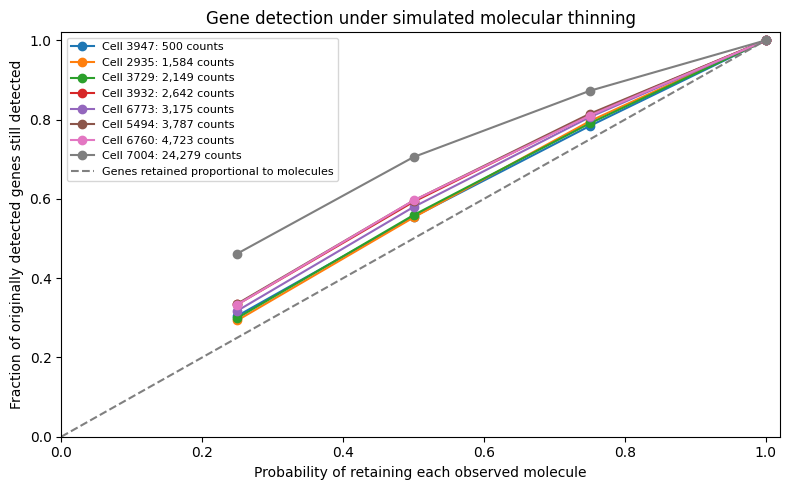

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

for cell_index in measurement_cell_indices:
    rows = thinning_summary[
        thinning_summary["cell_index"] == cell_index
    ].sort_values("retention_probability")

    original_total = int(rows["original_counts"].iloc[0])

    ax.plot(
        rows["retention_probability"],
        rows["mean_fraction_genes_retained"],
        marker="o",
        label=f"Cell {cell_index}: {original_total:,} counts",
    )

ax.plot(
    [0, 1], [0, 1],
    linestyle="--", color="gray",
    label="Genes retained proportional to molecules",
)

ax.set(
    xlabel="Probability of retaining each observed molecule",
    ylabel="Fraction of originally detected genes still detected",
    title="Gene detection under simulated molecular thinning",
    xlim=(0, 1.02),
    ylim=(0, 1.02),
)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Interpretation of plot: Lower molecular detection removes genes from observations (obviously), but the main conclusion is that it removes samples more samples from genes with 1-count, explaining the differences we saw in datasets.

### 3. Binning


### 4. Biologocal cell composition

In [10]:
META = Path(
    "/home/akash1/projects/rrg-tperkins/dgladish/Projects/MSc/"
    "benchmarking_spatial_scale/metadata/sample_md.tsv"
)

sample_metadata = pd.read_csv(META, sep="\t")

matched_sample = sample_metadata.loc[
    sample_metadata["sample_id"].eq(SAMPLE_ID)
]
assert len(matched_sample) == 1
sample_record = matched_sample.iloc[0]

cell_context = measurement_qc.copy()

cell_context["case_id"] = sample_record["case_id"]
cell_context["sample_id"] = SAMPLE_ID

# primary_site describes the disease/specimen context,
# not the identity of every individual cell.
cell_context["disease_primary_site"] = sample_record["primary_site"]
cell_context["sample_diagnosis"] = sample_record[
    "diagnoses.0.primary_diagnosis"
]
cell_context["sample_wgd_status"] = sample_record["wgd_status"]

# These specimen properties were confirmed by the GDC response.
cell_context["specimen_type"] = "Primary Tumor"
cell_context["preservation_method"] = "Snap Frozen"

# Keep unresolved biological labels explicit.
cell_context["cell_type"] = "unassigned"
cell_context["cell_type_source"] = "none"
cell_context["malignant_status"] = "unresolved"

copykat_path = RNA_DIR / "copykatOUT" / "_copykat_prediction.txt"
copykat = pd.read_csv(copykat_path, sep="\t", dtype=str)

assert {"cell.names", "copykat.pred"}.issubset(copykat.columns)
assert copykat["cell.names"].is_unique

prediction_by_barcode = copykat.set_index("cell.names")["copykat.pred"]
cell_context["copykat_prediction"] = cell_context.index.map(
    prediction_by_barcode
)

# Barcodes are only unique within their sample.
cell_context["cell_id"] = (
    SAMPLE_ID + ":" + cell_context.index.astype(str)
)
assert cell_context["cell_id"].is_unique

cell_context.to_csv(OUT / "cell_context.csv")

display(cell_context.head())
display(
    cell_context.groupby("copykat_prediction", dropna=False)[
        [
            "total_counts",
            "detected_genes",
            "fraction_detected_genes_count_one",
        ]
    ].agg(["count", "median"])
)

,total_counts,detected_genes,fraction_features_zero,fraction_detected_genes_count_one,fraction_total_counts_in_count_one_genes,case_id,sample_id,disease_primary_site,sample_diagnosis,sample_wgd_status,specimen_type,preservation_method,cell_type,cell_type_source,malignant_status,copykat_prediction,cell_id
barcode,,,,,,,,,,,,,,,,,
AAACCCAAGAAGTGTT-1,2794.0,1511,0.975091,0.671079,0.362921,C3N-00148,C3N-00148-01,Kidney,"Renal cell carcinoma, NOS",WGD+,Primary Tumor,Snap Frozen,unassigned,none,unresolved,diploid,C3N-00148-01:AAACCCAAGAAGTGTT-1
AAACCCAAGCCTGTCG-1,1712.0,1047,0.982740,0.775549,0.474299,C3N-00148,C3N-00148-01,Kidney,"Renal cell carcinoma, NOS",WGD+,Primary Tumor,Snap Frozen,unassigned,none,unresolved,diploid,C3N-00148-01:AAACCCAAGCCTGTCG-1
AAACCCAAGCGCTGCT-1,2032.0,1083,0.982146,0.771006,0.410925,C3N-00148,C3N-00148-01,Kidney,"Renal cell carcinoma, NOS",WGD+,Primary Tumor,Snap Frozen,unassigned,none,unresolved,diploid,C3N-00148-01:AAACCCAAGCGCTGCT-1
AAACCCAAGTTCCGGC-1,4607.0,2466,0.959347,0.678021,0.362926,C3N-00148,C3N-00148-01,Kidney,"Renal cell carcinoma, NOS",WGD+,Primary Tumor,Snap Frozen,unassigned,none,unresolved,aneuploid,C3N-00148-01:AAACCCAAGTTCCGGC-1
AAACCCACAAGCGCTC-1,3452.0,1982,0.967326,0.746216,0.428447,C3N-00148,C3N-00148-01,Kidney,"Renal cell carcinoma, NOS",WGD+,Primary Tumor,Snap Frozen,unassigned,none,unresolved,diploid,C3N-00148-01:AAACCCACAAGCGCTC-1


total_counts         detected_genes          \
                          count  median          count  median   
copykat_prediction                                               
aneuploid                  4106  3367.0           4106  1818.0   
diploid                    2100  2916.0           2100  1590.0   
not.defined                1378  1456.0           1378   876.5   
NaN                          14  1556.5             14   136.5   

                   fraction_detected_genes_count_one            
                                               count    median  
copykat_prediction                                              
aneuploid                                       4106  0.739005  
diploid                                         2100  0.730650  
not.defined                                     1378  0.813706  
NaN                                               14  0.799107

In [12]:
sample_uuid = "01dc2054-7387-46dc-8e10-7300f0c49432"

filters = {
    "op": "and",
    "content": [
        {
            "op": "in",
            "content": {
                "field": "cases.samples.sample_id",
                "value": [sample_uuid],
            },
        },
        {
            "op": "in",
            "content": {
                "field": "data_category",
                "value": ["Transcriptome Profiling"],
            },
        },
    ],
}

fields = [
    "file_id",
    "file_name",
    "data_type",
    "data_format",
    "experimental_strategy",
    "file_size",
    "access",
    "analysis.workflow_type",
]

params = {
    "filters": json.dumps(filters),
    "fields": ",".join(fields),
    "size": 100,
}

url = "https://api.gdc.cancer.gov/files?" + urlencode(params)

with urllib.request.urlopen(url, timeout=30) as response:
    related_response = json.load(response)

(OUT / "related_expression_files.json").write_text(
    json.dumps(related_response, indent=2)
)

hits = related_response["data"]["hits"]
total = related_response["data"]["pagination"]["total"]

related_files = pd.json_normalize(hits)
if hits:
    related_files["size_MiB"] = related_files["file_size"] / 1024**2

    columns = [
        "file_id", "file_name", "data_type", "data_format",
        "experimental_strategy", "analysis.workflow_type",
        "size_MiB", "access",
    ]

    with pd.option_context("display.max_colwidth", 100):
        display(
            related_files.reindex(columns=columns)
            .sort_values(["data_type", "file_name"])
        )
else:
    print("No related files returned.")

print(f"Displayed {len(hits)} of {total} matching files.")
if total > len(hits):
    print("More results exist; retrieve the remaining pages before concluding.")

related_files.to_csv(OUT / "related_expression_files.csv", index=False)

,file_id,file_name,data_type,data_format,experimental_strategy,analysis.workflow_type,size_MiB,access
4,a5da1912-76a3-40c1-b83a-11beafaa6c8a,seurat.deg.tsv,Differential Gene Expression,TSV,scRNA-Seq,Seurat - 10x Chromium,1.000292,open
6,dbe28c52-cdbf-477e-a728-9a61fd4a8139,50387e2c-95d5-4781-8c17-e8139fbe5712.qc_filtered_feature_bc_matrix.tar.gz,Gene Expression Quantification,MEX,scRNA-Seq,CellRanger - 10x Filtered Counts,38.605103,open
5,12355205-4cdc-4462-aab5-bc715845c061,682f51f8-5d1f-4b6f-909f-3ffb2645ebc3.rna_seq.augmented_star_gene_counts.tsv,Gene Expression Quantification,TSV,RNA-Seq,STAR - Counts,4.037493,open
8,af54b13d-9c57-4352-bb09-f311c5301006,raw_feature_bc_matrix.tar.gz,Gene Expression Quantification,MEX,scRNA-Seq,CellRanger - 10x Raw Counts,80.363173,open
2,512b44a4-99f9-4613-a349-e8cb60db3d52,9f449c9d-e343-470c-adfb-b26be384d451.mirnaseq.isoforms.quantification.txt,Isoform Expression Quantification,TSV,miRNA-Seq,BCGSC miRNA Profiling,0.696272,open
1,7f1eb380-9931-4f13-8756-e9dd3734e7ca,50387e2c-95d5-4781-8c17-e8139fbe5712.seurat.1000x1000.loom,Single Cell Analysis,HDF5,scRNA-Seq,Seurat - 10x Chromium,85.555032,open
3,5846d458-aa26-49b9-811a-97d84a7ab41e,seurat.analysis.tsv,Single Cell Analysis,TSV,scRNA-Seq,Seurat - 10x Chromium,2.784996,open
7,6220438f-16cb-4e18-9f12-1831ad0fc5cd,682f51f8-5d1f-4b6f-909f-3ffb2645ebc3.rna_seq.star_splice_junctions.tsv.gz,Splice Junction Quantification,TSV,RNA-Seq,STAR - Counts,2.892549,controlled
0,1b0df8f4-931a-4e05-8943-f06dcbd8e3ca,9f449c9d-e343-470c-adfb-b26be384d451.mirnaseq.mirnas.quantification.txt,miRNA Expression Quantification,TSV,miRNA-Seq,BCGSC miRNA Profiling,0.048246,open


Displayed 9 of 9 matching files.


In [16]:
annotation_dir = OUT / "gdc_secondary_analysis"
annotation_dir.mkdir(parents=True, exist_ok=True)

analysis_files = {
    "seurat.analysis.tsv": "5846d458-aa26-49b9-811a-97d84a7ab41e",
    "seurat.deg.tsv": "a5da1912-76a3-40c1-b83a-11beafaa6c8a",
}

for filename, file_id in analysis_files.items():
    destination = annotation_dir / filename

    if destination.exists():
        print("Already present:", destination)
        continue

    request = urllib.request.Request(
        f"https://api.gdc.cancer.gov/data/{file_id}",
        headers={"Accept": "application/octet-stream"},
    )

    # Download completely before giving the file its final name.
    temporary = destination.with_suffix(destination.suffix + ".part")

    with urllib.request.urlopen(request, timeout=60) as response:
        with temporary.open("wb") as handle:
            while chunk := response.read(1024 * 1024):
                handle.write(chunk)

    temporary.replace(destination)
    print("Downloaded:", destination)

Downloaded: /home/akash1/scgpt-cna/measurement_analysis/C3N-00148-01/gdc_secondary_analysis/seurat.analysis.tsv


RemoteDisconnected: Remote end closed connection without response

In [14]:
seurat_analysis = pd.read_csv(
    annotation_dir / "seurat.analysis.tsv",
    sep="\t",
    low_memory=False,
)

seurat_deg = pd.read_csv(
    annotation_dir / "seurat.deg.tsv",
    sep="\t",
    low_memory=False,
)

for name, table in [
    ("Seurat cell analysis", seurat_analysis),
    ("Seurat differential expression", seurat_deg),
]:
    print(f"\n{name}")
    print("Shape:", table.shape)
    print("Columns:", table.columns.tolist())
    print("Index type:", type(table.index).__name__)
    print("First index values:", table.index[:3].tolist())

    # Transpose a few rows so all column names remain easy to inspect.
    display(table.head(3).T)

FileNotFoundError: [Errno 2] No such file or directory: '/home/akash1/scgpt-cna/measurement_analysis/C3N-00148-01/gdc_secondary_analysis/seurat.analysis.tsv'

In [15]:
lab_barcodes = set(cell_context.index.astype(str))

candidates = {
    str(column): seurat_analysis[column]
    for column in seurat_analysis.columns
}

# Some TSV exports place barcodes in an unnamed first column
# that Pandas interprets as the index.
if not isinstance(seurat_analysis.index, pd.RangeIndex):
    candidates["<DataFrame index>"] = pd.Series(
        seurat_analysis.index.to_numpy()
    )

overlap_rows = []

for name, values in candidates.items():
    identifiers = values.dropna().astype(str)
    matching = identifiers[identifiers.isin(lab_barcodes)]

    if len(matching):
        overlap_rows.append({
            "candidate_barcode_field": name,
            "n_matching_rows": len(matching),
            "n_unique_matching_barcodes": matching.nunique(),
            "n_nonmissing_values": len(identifiers),
            "all_nonmissing_values_unique": identifiers.is_unique,
            "fraction_lab_cells_matched": (
                matching.nunique() / len(lab_barcodes)
            ),
        })

barcode_overlap = pd.DataFrame(overlap_rows)

if barcode_overlap.empty:
    print("No exact barcode matches found.")
    print("Inspect identifiers before attempting any barcode conversion.")
else:
    display(
        barcode_overlap.sort_values(
            "n_unique_matching_barcodes",
            ascending=False,
        )
    )

NameError: name 'seurat_analysis' is not defined